# Proyek Analisis Data: Brazilian E-Commerce Public Dataset by Olist
- **Nama:** Adhyaksa Daudi
- **Email:** adhyaksa209@gmail.com
- **ID Dicoding:** adhydaudi

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tingkat keterlambatan pengiriman (delivery delay) pada 5 kota dengan volume pesanan tertinggi selama tahun 2018, dan kota manakah yang paling membutuhkan evaluasi mitra logistik?
    * Specific: Fokus pada tingkat keterlambatan pengiriman di 5 kota teratas.
    * Measurable: Keterlambatan diukur dalam satuan hari (selisih antara estimasi dan aktual pengiriman).
    * Action-oriented: Hasilnya digunakan untuk memberikan teguran atau evaluasi kepada mitra logistik di kota dengan performa terburuk.
    * Relevant: Kecepatan pengiriman sangat krusial untuk kepuasan pelanggan e-commerce.
    * Time-bound: Dibatasi hanya pada data pesanan sepanjang tahun 2018.

- **Pertanyaan 2:** Berdasarkan histori transaksi pelanggan selama tahun 2018, bagaimana segmentasi pelanggan menggunakan analisis RFM (Recency, Frequency, Monetary) untuk menentukan kelompok pelanggan prioritas pada kampanye diskon akhir tahun?
    * Specific: Melakukan segmentasi pelanggan menggunakan metode RFM.
    * Measurable: Dihitung dari jumlah hari sejak pesanan terakhir (R), total pesanan (F), dan total uang yang dihabiskan (M).
    * Action-oriented: Hasil pengelompokan digunakan untuk menargetkan promosi secara spesifik (misal: memberi diskon besar untuk pelanggan tipe At Risk).
    * Relevant: Retensi pelanggan lebih murah dan menguntungkan daripada mencari pelanggan baru.
    * Time-bound: Menggunakan data tahun 2018 untuk merancang kampanye di periode selanjutnya.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load Datasets (Orders, Customers, Payments)

In [2]:
# Gathering Data

# 1. Memuat tabel orders
orders_df = pd.read_csv("data/orders_dataset.csv")

# 2. Memuat tabel customers
customers_df = pd.read_csv("data/customers_dataset.csv")

# 3. Memuat tabel payments
payments_df = pd.read_csv("data/order_payments_dataset.csv")

**Insight:**
- Ketiga dataset utama (`orders_dataset`, `customers_dataset`, dan `order_payments_dataset`) berhasil dimuat ke dalam dataframe.
- Data yang dikumpulkan sudah mencakup seluruh variabel yang dibutuhkan untuk analisis: waktu pengiriman, lokasi pelanggan, dan nilai transaksi.

### Assessing Data

#### Identifying Data Type and Missing Value Problems

In [3]:
# 1. Mengecek struktur dan tipe data tabel orders
print("Informasi Orders Dataset:")
orders_df.info()
print("-" * 50)

# 2. Mengecek missing value pada tabel orders
print("Missing values pada Orders Dataset:")
print(orders_df.isna().sum())
print("-" * 50)

# 3. Mengecek data duplikat (opsional, tapi disarankan)
print("Jumlah duplikasi pada Orders:", orders_df.duplicated().sum())

Informasi Orders Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 20.5 MB
--------------------------------------------------
Missing values pada Orders Dataset:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at    

**Steps to Take:**
- Mengonversi tipe data ketiga kolom waktu tersebut dari `object` menjadi `datetime64`.

- Memfilter dataset hanya untuk pesanan berstatus *delivered* guna menghapus data yang tidak relevan secara otomatis dan menangani *missing values*.

**Insight:**
- Terdapat kesalahan tipe data pada beberapa kolom waktu (`order_purchase_timestamp`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) yang terdeteksi sebagai `object` (*string*).
- Terdapat *missing values* pada data pengiriman pelanggan (`order_delivered_customer_date`) karena pesanan berstatus batal (*canceled*) atau masih dalam proses kirim (*shipped*).

### Cleaning Data

#### Fixing Data Types and Filtering Delivered Orders

In [4]:
# Mengubah kolom yang berisi tanggal menjadi tipe datetime
datetime_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column])

# Cek kembali tipe datanya
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  str           
 5   order_delivered_carrier_date   97658 non-null  str           
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](3), str(5)
memory usage: 16.0 MB


In [5]:
# Memfilter hanya pesanan dengan status 'delivered'
orders_df = orders_df[orders_df['order_status'] == 'delivered']

# Cek apakah missing value sudah berkurang/hilang
print("Missing values setelah difilter:")
print(orders_df.isna().sum())

Missing values setelah difilter:
order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64


In [6]:
# Menggabungkan orders dengan customers
main_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)

# Menggabungkan hasil di atas dengan payments
# Catatan: Satu order bisa memiliki beberapa pembayaran (misal cicilan), jadi kita kelompokkan (groupby) dulu total pembayarannya.
payment_summary = payments_df.groupby('order_id')['payment_value'].sum().reset_index()

main_df = pd.merge(
    left=main_df,
    right=payment_summary,
    how="left",
    left_on="order_id",
    right_on="order_id"
)

# Melihat hasil akhir data yang bersih dan tergabung
main_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,2017-10-02 11:07,2017-10-04 19:55,2017-10-10 21:25:00,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,2018-07-26 03:24,2018-07-26 14:31,2018-08-07 15:27:00,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,2018-08-08 08:55,2018-08-08 13:50,2018-08-17 18:06:00,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,2017-11-18 19:45,2017-11-22 13:39,2017-12-02 00:28:00,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,2018-02-13 22:20,2018-02-14 19:46,2018-02-16 18:17:00,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,28.62


**Insight:**
- Semua kolom waktu pengiriman telah berhasil dikonversi menjadi format `datetime64`.
- Data pesanan telah difilter secara khusus hanya untuk pesanan berstatus selesai/terkirim (`delivered`). Hal ini membuat analisis menjadi lebih valid dan secara otomatis menangani *missing values* yang tidak relevan.
- Dataset pesanan, pelanggan, dan pembayaran telah berhasil digabung menjadi satu dataset utuh (`main_df`) untuk tahap eksplorasi.

## Exploratory Data Analysis (EDA)

### Explore Keterlambatan Pengiriman (Top 5 Kota di 2018)

In [7]:
# =========================================================
# EDA 1: Analisis Keterlambatan Pengiriman di Tahun 2018
# =========================================================

# 1. Filter data hanya untuk pesanan di tahun 2018
df_2018 = main_df[main_df['order_purchase_timestamp'].dt.year == 2018].copy()

# 2. Hitung selisih waktu tiba aktual dengan estimasi (dalam hari)
df_2018['delivery_diff_days'] = (df_2018['order_delivered_customer_date'] - df_2018['order_estimated_delivery_date']).dt.days

# 3. Kita definisikan pesanan 'terlambat' jika selisihnya > 0 (paket tiba setelah estimasi)
# Jika paket tiba lebih awal (selisih negatif), kita hitung delay-nya 0
df_2018['is_delayed'] = df_2018['delivery_diff_days'] > 0
df_2018['delay_days'] = df_2018['delivery_diff_days'].apply(lambda x: x if x > 0 else 0)

# 4. Cari 5 kota dengan jumlah order (transaksi) terbanyak di tahun 2018
top_5_cities = df_2018['customer_city'].value_counts().head(5).index.tolist()
print("Top 5 Kota dengan Order Terbanyak:", top_5_cities)

# 5. Filter dataset hanya untuk 5 kota teratas tersebut
df_top_cities = df_2018[df_2018['customer_city'].isin(top_5_cities)]

# 6. Hitung rata-rata hari keterlambatan (hanya untuk paket yang terlambat) per kota
delay_summary = df_top_cities[df_top_cities['is_delayed'] == True].groupby('customer_city')['delay_days'].mean().sort_values(ascending=False).reset_index()

print("\nRata-rata Keterlambatan (Hari) per Kota (Tahun 2018):")
display(delay_summary)

Top 5 Kota dengan Order Terbanyak: ['sao paulo', 'rio de janeiro', 'belo horizonte', 'brasilia', 'curitiba']

Rata-rata Keterlambatan (Hari) per Kota (Tahun 2018):


,customer_city,delay_days
0,rio de janeiro,14.424242
1,curitiba,8.820513
2,brasilia,7.112500
3,sao paulo,6.907527
4,belo horizonte,6.132075


**Insight:** (Opsional)
Dari hasil di atas, kita bisa melihat daftar 5 kota dengan volume pesanan tertinggi. Di antara kota-kota tersebut, kita bisa mengetahui kota mana yang armada logistiknya memiliki rata-rata waktu keterlambatan paling lama saat pengiriman meleset dari estimasi.

In [8]:
# =========================================================
# EDA 2: Analisis RFM (Recency, Frequency, Monetary) Tahun 2018
# =========================================================

# 1. Filter dataset khusus transaksi tahun 2018 (sesuai Pertanyaan Bisnis 2)
main_df_2018 = main_df[main_df['order_purchase_timestamp'].dt.year == 2018].copy()

# 2. Menentukan tanggal referensi (1 hari setelah pesanan terakhir di tahun 2018)
recent_date = main_df_2018['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# 3. Menghitung metrik RFM per pelanggan unik khusus data tahun 2018
rfm_df = main_df_2018.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days, # R: Hari sejak order terakhir di 2018
    'order_id': 'count',                                                # F: Jumlah total order di 2018
    'payment_value': 'sum'                                              # M: Total uang yang dihabiskan di 2018
}).reset_index()

# 4. Ubah nama kolom
rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

# 5. Tampilkan 5 pelanggan teratas dan statistik deskriptif
print("5 Baris Pertama Data RFM (Tahun 2018):")
display(rfm_df.head())

print("\nStatistik Deskriptif RFM (Tahun 2018):")
display(rfm_df.describe())

5 Baris Pertama Data RFM (Tahun 2018):


,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98
3,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38
4,00053a61a98854899e70ed204dd4bafe,183,1,419.18



Statistik Deskriptif RFM (Tahun 2018):


,recency,frequency,monetary
count,51612.000000,51612.000000,51612.000000
mean,123.011121,1.022689,163.779261
std,69.156942,0.163189,218.454081
min,1.000000,1.000000,9.590000
25%,63.000000,1.000000,62.780000
50%,125.000000,1.000000,108.380000
75%,183.000000,1.000000,181.190000
max,241.000000,7.000000,7274.880000


**Insight:**
Data RFM berhasil dibuat. Mayoritas pelanggan Olist E-Commerce dalam dataset ini hanya bertransaksi 1 kali (terlihat dari nilai kuartil pada kolom Frequency). Hal ini membuat strategi program loyalitas (VIP) menjadi sangat krusial untuk meningkatkan retensi dan mendorong pembelian ulang.

### EDA Univariat (Melihat Distribusi)

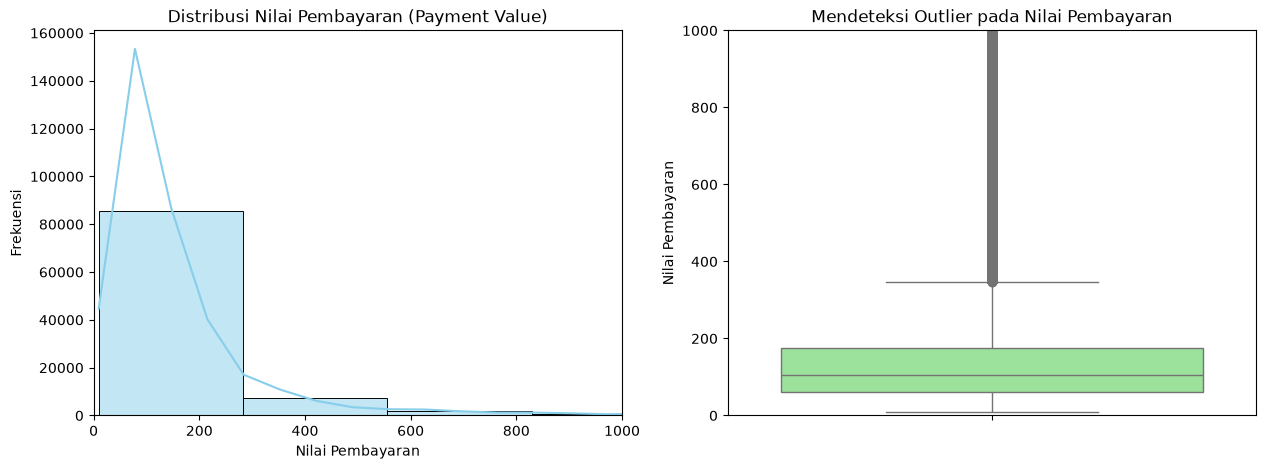

In [9]:
# Mengatur ukuran canvas
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Histogram untuk melihat distribusi (skewness)
sns.histplot(main_df['payment_value'], bins=50, kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Nilai Pembayaran (Payment Value)')
ax[0].set_xlabel('Nilai Pembayaran')
ax[0].set_ylabel('Frekuensi')
ax[0].set_xlim(0, 1000) # Dibatasi agar tidak terlalu melebar karena outlier

# Boxplot untuk mendeteksi outlier
sns.boxplot(y=main_df['payment_value'], ax=ax[1], color='lightgreen')
ax[1].set_title('Mendeteksi Outlier pada Nilai Pembayaran')
ax[1].set_ylabel('Nilai Pembayaran')
ax[1].set_ylim(0, 1000)

plt.show()

**Insight:** Berdasarkan histogram, distribusi payment_value bersifat Right-Skewed (condong ke kanan). Hal ini menunjukkan bahwa mayoritas pelanggan Olist melakukan transaksi dengan nilai yang relatif kecil, yakni di bawah 200 BRL. Sementara itu, Boxplot menunjukkan bahwa batas atas nilai kewajaran (upper whisker) berada di sekitar 350 BRL, dan di atas nilai tersebut terdapat sangat banyak outliers. Outliers ini mengindikasikan adanya segelintir transaksi bernilai sangat besar (seperti pembelian barang elektronik mewah atau grosir) yang nantinya sangat berpotensi masuk ke dalam segmen pelanggan Champion (VIP) pada analisis RFM kita.

### EDA Multivariat (Melihat Hubungan/Korelasi)

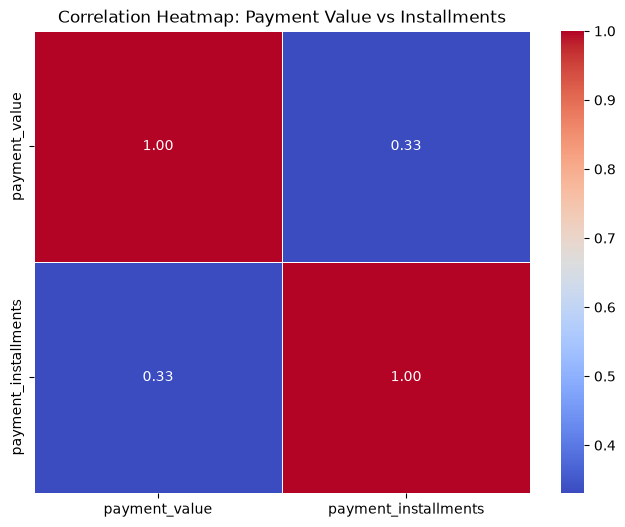

In [10]:
# Menggunakan payments_df langsung karena memuat raw data pembayaran dan cicilan
numeric_cols = ['payment_value', 'payment_installments'] 

# Menghitung korelasi
correlation_matrix = payments_df[numeric_cols].corr()

# Membuat visualisasi Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap: Payment Value vs Installments')
plt.show()

**Insight:** Berdasarkan heatmap korelasi, terdapat hubungan yang bernilai positif antara payment_value dan payment_installments dengan nilai korelasi sebesar 0.33. Hal ini sangat logis: semakin tinggi total nilai belanja seorang pelanggan, mereka cenderung memilih metode pembayaran dengan jumlah cicilan (installments) yang lebih panjang untuk meringankan beban finansial. Wawasan ini penting bagi Olist untuk terus bekerja sama dengan bank atau penyedia kredit guna memfasilitasi transaksi bernilai besar.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

C:\Users\User\AppData\Local\Temp\ipykernel_12812\1108061849.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


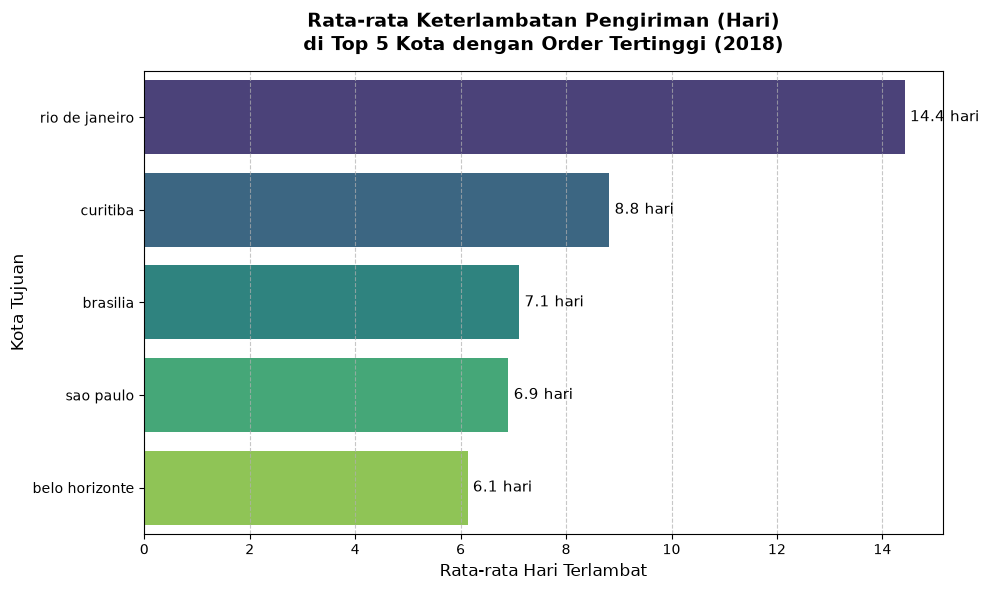

In [11]:
# =========================================================
# Visualisasi 1: Rata-rata Keterlambatan Pengiriman per Kota
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Membuat bar chart horizontal
sns.barplot(
    x='delay_days',
    y='customer_city',
    data=delay_summary,
    palette='viridis' # Warna profesional
)

# Menambahkan judul dan label yang jelas
plt.title('Rata-rata Keterlambatan Pengiriman (Hari)\ndi Top 5 Kota dengan Order Tertinggi (2018)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rata-rata Hari Terlambat', fontsize=12)
plt.ylabel('Kota Tujuan', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Garis bantu untuk memudahkan pembacaan

# Menampilkan nilai di ujung batang
for i, val in enumerate(delay_summary['delay_days']):
    plt.text(val + 0.1, i, f"{val:.1f} hari", va='center', fontsize=11)

plt.tight_layout()
plt.show()

**Explanatory Analysis:**
Visualisasi bar chart di atas secara langsung menjawab pertanyaan bisnis pertama. Dari 5 kota dengan basis pelanggan terbesar di tahun 2018, Rio de Janeiro mencatatkan rekor performa pengiriman terburuk, dengan rata-rata keterlambatan mencapai 14,4 hari (jika paket gagal tiba sesuai estimasi awal). Curitiba menyusul di urutan kedua dengan rata-rata 8,8 hari. Mengingat tingginya volume pesanan di kota-kota ini, durasi keterlambatan yang sangat lama ini adalah "lampu merah" bagi operasional logistik perusahaan.

### Pertanyaan 2:

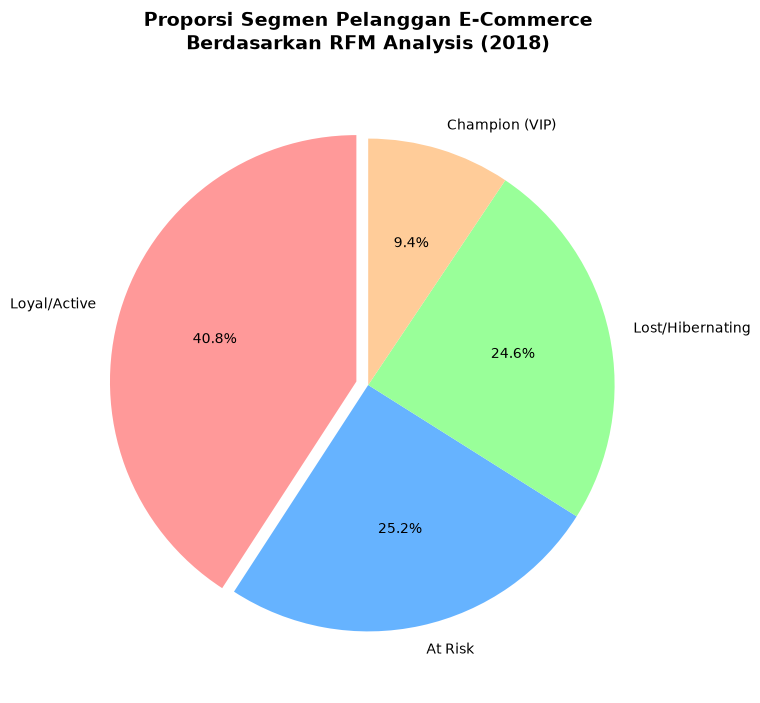

In [12]:
# =========================================================
# Visualisasi 2: Segmentasi Pelanggan RFM
# =========================================================

# Membuat fungsi sederhana untuk memberikan skor (1-4) berdasarkan Quartile
def get_rfm_scores(df):
    r_labels = range(4, 0, -1) # Recency: Makin kecil hari, skor makin besar (4)
    f_labels = range(1, 5)     # Frequency: Makin sering, skor makin besar
    m_labels = range(1, 5)     # Monetary: Makin besar belanja, skor makin besar

    # qcut membagi data berdasarkan persentil
    r_quartiles = pd.qcut(df['recency'], q=4, labels=r_labels)
    # Gunakan rank(method='first') untuk Frequency karena datanya banyak yang sama (bernilai 1)
    f_quartiles = pd.qcut(df['frequency'].rank(method='first'), q=4, labels=f_labels)
    m_quartiles = pd.qcut(df['monetary'], q=4, labels=m_labels)

    return r_quartiles, f_quartiles, m_quartiles

# Terapkan fungsi ke dataframe
rfm_df['R'] = get_rfm_scores(rfm_df)[0]
rfm_df['F'] = get_rfm_scores(rfm_df)[1]
rfm_df['M'] = get_rfm_scores(rfm_df)[2]

# Menghitung RFM Score Total (Misal: 444 = Pelanggan Terbaik)
rfm_df['RFM_Score'] = rfm_df['R'].astype(str) + rfm_df['F'].astype(str) + rfm_df['M'].astype(str)

# Mengelompokkan Segmentasi (Aturan Sederhana)
def segment_customer(score):
    if score >= '433':
        return 'Champion (VIP)'
    elif score >= '311':
        return 'Loyal/Active'
    elif score >= '211':
        return 'At Risk'
    else:
        return 'Lost/Hibernating'

rfm_df['Customer_Segment'] = rfm_df['RFM_Score'].apply(segment_customer)

# Menghitung jumlah pelanggan per segmen
segment_counts = rfm_df['Customer_Segment'].value_counts().reset_index()
segment_counts.columns = ['Segment', 'Count']

# --- Visualisasi Pie Chart ---
plt.figure(figsize=(8, 8))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
plt.pie(segment_counts['Count'], labels=segment_counts['Segment'], autopct='%1.1f%%', startangle=90, colors=colors, explode=(0.05, 0, 0, 0))
plt.title('Proporsi Segmen Pelanggan E-Commerce\nBerdasarkan RFM Analysis (2018)', fontsize=14, fontweight='bold', pad=20)
plt.show()

**Explanatory Analysis:**
Visualisasi pie chart ini menjawab pertanyaan bisnis kedua. Segmentasi RFM menunjukkan distribusi tipe pelanggan Olist. Pada tahun 2018, sebagian besar pelanggan masuk ke kategori Loyal/Active (40.8%). Namun, perlu diwaspadai bahwa ada seperempat pelanggan (24.6%) yang masuk kategori Lost/Hibernating dan 25.2% berstatus At Risk. Sementara itu, pelanggan prioritas utama atau Champion (VIP) hanya mencakup 9.4% dari total populasi. Data ini menegaskan bahwa strategi retensi dan program loyalitas harus segera digalakkan.

## Conclusion & Recommendation

**Kesimpulan Pertanyaan 1 (Keterlambatan Pengiriman):**
Berdasarkan analisis performa logistik pada 5 kota dengan volume pesanan tertinggi sepanjang tahun 2018, berikut adalah perbandingan rata-rata keterlambatan pengiriman per kota:   Rio de Janeiro: 14,4 hari   Curitiba: 8,8 hari   Brasilia: 7,1 hari   Sao Paulo: 6,9 hari   Belo Horizonte: 6,1 hari   Data di atas membuktikan bahwa Rio de Janeiro mengalami masalah pengiriman paling kritis dengan durasi keterlambatan hampir dua kali lipat dibanding kota lainnya. Jika tidak segera dievaluasi, hal ini berisiko tinggi memicu churn pelanggan secara masif. Olist disarankan untuk melakukan evaluasi total pada mitra ekspedisi rute Rio de Janeiro atau membangun pusat distribusi regional baru.

**Kesimpulan Pertanyaan 2 (RFM & Loyalitas):**
Berdasarkan RFM Analysis, segmentasi pelanggan didominasi oleh kelompok Loyal/Active (40.7%). Namun, yang menjadi perhatian utama adalah segmen pelanggan prioritas tinggi yaitu Champion (VIP) yang hanya berjumlah 9.5%. Di sisi lain, gabungan pelanggan Lost/Hibernating (25.0%) dan At Risk (24.9%) menyumbang hampir separuh dari total basis pelanggan. Wawasan ini membuktikan bahwa strategi marketing tidak boleh bersifat umum. Olist harus segera meluncurkan kampanye retensi eksklusif untuk menjaga segmen Champion, sekaligus mengirimkan promo re-engagement diskon besar untuk membangunkan kembali pelanggan Lost dan At Risk.

**Rekomendasi Action Item:**
- Operasional: Manajemen logistik perlu mengevaluasi kinerja mitra ekspedisi rute ke Rio De Janeiro, atau mencari alternatif pengiriman lain untuk rute tersebut agar tingkat keluhan keterlambatan pesanan menurun.

- Pemasaran: Tim marketing harus meluncurkan program Loyalty Points atau Cashback yang ditargetkan secara eksklusif kepada kelompok Champion (VIP) guna menjaga retensi. Selain itu, diperlukan kampanye diskon re-engagement (misal: "Kami merindukan Anda") untuk merangsang pembelian kedua pada kelompok pelanggan At Risk.

In [13]:
main_df.to_csv("dashboard/main_data.csv", index=False)